### importing numpy and sep

In [1]:
import numpy as np
import sep

### imoprting astropy's fits and matplotlib

In [2]:
from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib import rcParams

%matplotlib inline

#set consistent canvas size
rcParams['figure.figsize'] = [10.,8.]

### Locating file and extracting it's data by placing it into a Numpy array (data_1)

In [3]:
#define file name
image = 'image.fits'

# read image into standard 2d numpy array
#read in data
hdu_1 = fits.open(image)

#get image data
data_1 = hdu_1[0].data


ESO-LOG 00:00:00> DATE         = '1992-10-26'  / Mon Oct 26, 1992                [astropy.io.fits.card]
ESO-LOG 03:04:08>-START EXPO EMMI RED          / Start exp. on EMMI Red CC       [astropy.io.fits.card]
ESO-LOG 03:04:09> EXPO EMMI RED NO = 24887     / Exp. num. on EMMI Red CCD       [astropy.io.fits.card]
ESO-LOG 03:10:52>-STOP EXPO EMMI RED           / Stop exp. on EMMI Red CCD       [astropy.io.fits.card]


### Taking the mean and standard deviation of the data. plt.imshow is plotting the data visually; interpolation preserves visual pixel quality of the image; cmap makes the image black and white; vmin sets the minimum value of data displayed as black; vmax sets the maximum value of data displayed as white

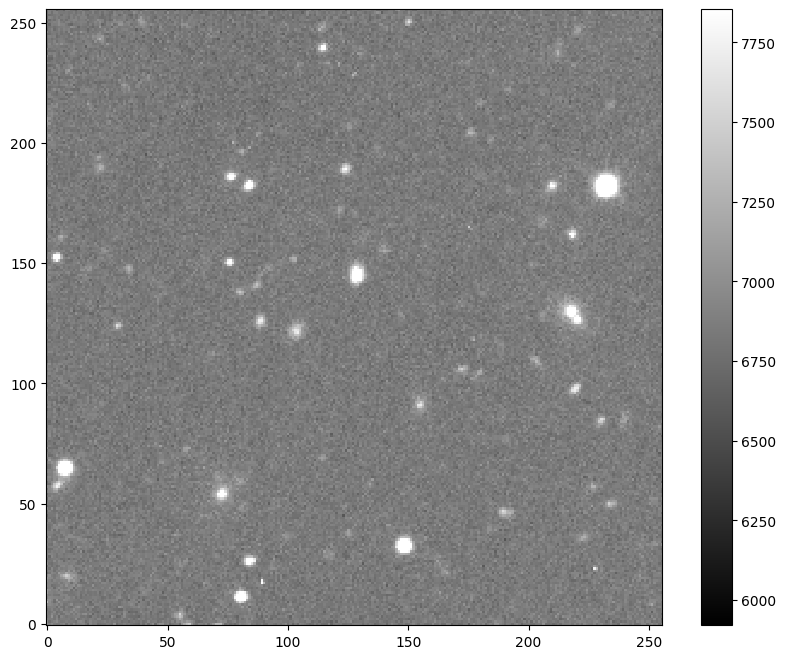

In [4]:
# show image 
m, s = np.mean(data_1), np.std(data_1)
plt.imshow(data_1, interpolation='nearest', cmap='gray' , vmin=m-s, vmax=m+s, origin='lower')
plt.colorbar();

plt.savefig('tutorial_im-1.png')

# Background Subtraction

### figuring out what the background sky level is and how much noise there is in order to detect objects in the sky later

In [5]:
# measure a spatially varying background on the image

bkg = sep.Background(data_1)

In [6]:
# get a "global" mean and noise of the image background:
print(bkg.globalback)
print(bkg.globalrms)

6852.04931640625
65.46174621582031


In [7]:
# evaluate background as 2-d array, same size as original image
bkg_image = bkg.back()

### showing the smooth, interpolated background

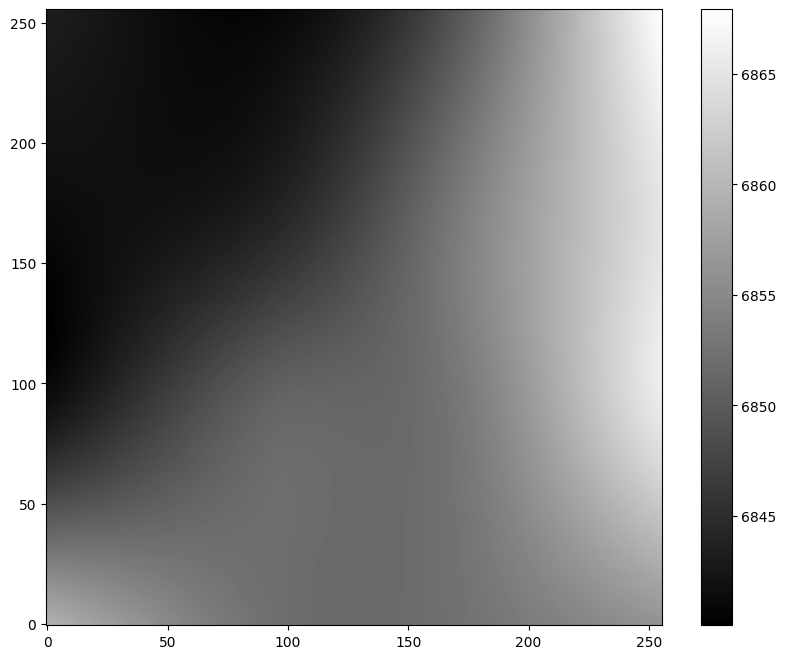

In [8]:
# show the background
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar();

plt.savefig('tutorial_im-2.png')

### getting the root mean square of the background noise

In [9]:
# evaluate the background noise as 2-d array, same size as original image
bkg_rms = bkg.rms()

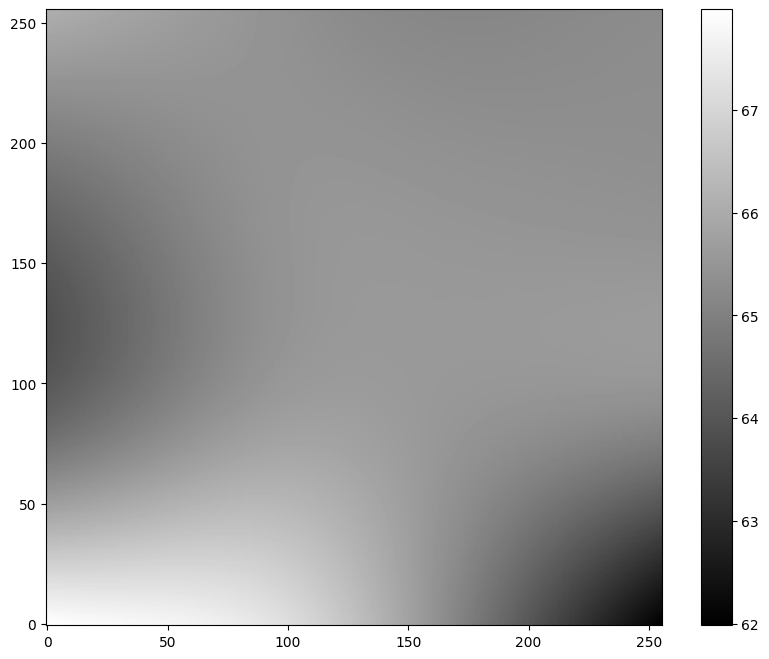

In [10]:
# show background noise
plt.imshow(bkg_rms, interpolation='nearest', cmap='gray',origin='lower')
plt.colorbar();

plt.savefig('tutorial_im-3.png')

### subtracting background from data array

In [11]:
# subtract the background
data_sub = data_1 - bkg

# Detecting Objects

### setting a detection threshhold; extracting values of data that are part of the 'background-subtracted' data and setting them as the objects

In [12]:
objects = sep.extract(data_sub, 1.5, err=bkg.globalrms)

In [13]:
# how many objects were detected
len(objects)

68

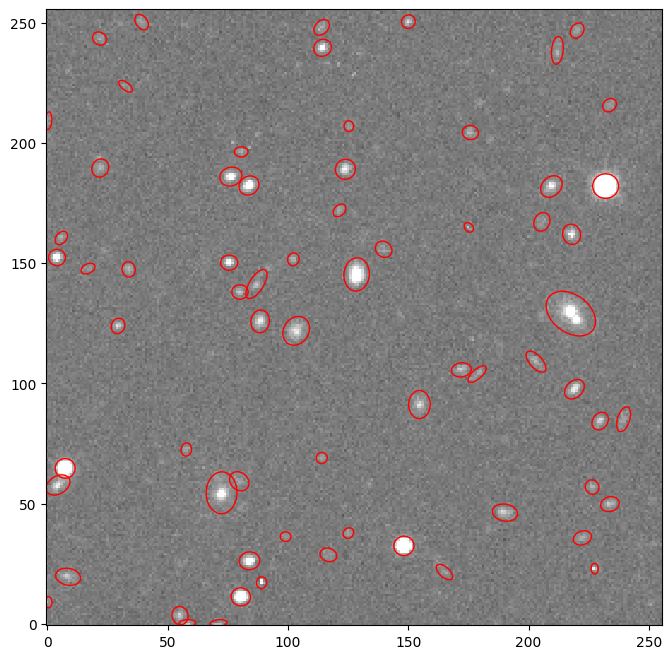

In [14]:
from matplotlib.patches import Ellipse

# plot backgroundsubtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray', vmin=m-s, vmax=m+s, origin='lower')

# plot an ellipse for each object
for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]),
                width=6*objects['a'][i],
                height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

plt.savefig('tutorial_im-4.png')

# Aperture Photometry

In [15]:
flux, fluxerr, flag = sep.sum_circle(data_sub, objects['x'], objects['y'],
                                    3.0, err=bkg.globalrms, gain=1.0)

In [16]:
# show the first 10 objects results:
for i in range(10):
    print("object {:d}: flux = {:f} +/- {:f}".format(i,flux[i], fluxerr[i]))

object 0: flux = 2249.157852 +/- 291.027799
object 1: flux = 3092.217500 +/- 291.592199
object 2: flux = 5949.861113 +/- 356.561993
object 3: flux = 1851.419824 +/- 295.028805
object 4: flux = 72736.380312 +/- 440.172199
object 5: flux = 3860.756895 +/- 352.163163
object 6: flux = 6418.902715 +/- 357.458957
object 7: flux = 2210.714238 +/- 350.791233
object 8: flux = 2741.609297 +/- 352.277749
object 9: flux = 20916.877363 +/- 376.966141
